# Setup

In [ ]:
!apt update -q
!apt-get install -q openjdk-11-jdk-headless

Hit:1 http://archive.ubuntu.com/ubuntu noble InRelease
Get:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Hit:3 https://cli.github.com/packages stable InRelease
Get:4 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:5 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:6 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:7 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Get:9 http://archive.ubuntu.com/ubuntu noble-updates/multiverse amd64 Packages [61.7 kB]
Get:10 http://archive.ubuntu.com/ubuntu noble-updates/universe amd64 Packages [2,166 kB]
Get:11 http://archive.ubuntu.com/ubuntu noble-updates/restricted amd64 Packages [2,231 kB]
Get:12 http://archive.ubuntu.com/ubuntu noble-updates/main amd64 Packages [1,728 kB]
Get:13 http://archive.ubuntu.com/ubuntu noble-backports/multiverse amd64 Pa

In [ ]:
!java -version
!javac -version

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
javac 21.0.12.1


# Configure your Twelve Data API key by running the below code cell

In [ ]:
from getpass import getpass
import os

os.environ["TWELVE_DATA_API_KEY"] = getpass("Enter your Twelve Data API key: ")

Enter your Twelve Data API key: ··········


# Writing Java file

For loop iterations can be edited to change the amount of data points collected.

In [ ]:
%%writefile App.java
import java.net.URI;
import java.net.http.HttpClient;
import java.net.http.HttpRequest;
import java.net.http.HttpResponse;
import java.time.Instant;
import java.util.LinkedList;
import java.util.Queue;
import java.util.regex.Matcher;
import java.util.regex.Pattern;

public class App {
    static class MarketDataPoint {
        double price;
        Instant timestamp;

        MarketDataPoint(double price, Instant timestamp) {
            this.price = price;
            this.timestamp = timestamp;
        }

        @Override
        public String toString() {
            return "price=" + price + ", timestamp=" + timestamp;
        }
    }

    private static final Pattern PRICE_PATTERN =
            Pattern.compile("\"price\"\\s*:\\s*\"?([0-9]+(?:\\.[0-9]+)?)\"?");

    public static void main(String[] args) throws Exception {
        String apiKey = System.getenv("TWELVE_DATA_API_KEY");

        if (apiKey == null || apiKey.isBlank()) {
            System.out.println("API key not found. Please set the TWELVE_DATA_API_KEY environment variable.");
            return;
        }

        Queue<MarketDataPoint> marketDataQueue = new LinkedList<>();
        HttpClient client = HttpClient.newHttpClient();

        for (int i = 1; i <= 20; i++) {
            System.out.println("\nRequest " + i + " of 20");

            String url = "https://api.twelvedata.com/price?symbol=DIA&apikey=" + apiKey;

            HttpRequest request = HttpRequest.newBuilder()
                    .uri(URI.create(url))
                    .GET()
                    .build();

            HttpResponse<String> response = client.send(request, HttpResponse.BodyHandlers.ofString());

            System.out.println("HTTP status: " + response.statusCode());
            System.out.println("Raw response: " + response.body());

            if (response.statusCode() == 200) {
                Matcher matcher = PRICE_PATTERN.matcher(response.body());

                if (matcher.find()) {
                    double price = Double.parseDouble(matcher.group(1));
                    MarketDataPoint dataPoint = new MarketDataPoint(price, Instant.now());

                    marketDataQueue.add(dataPoint);

                    System.out.println("Added data point: " + dataPoint);
                    System.out.println("Current queue size: " + marketDataQueue.size());
                } else {
                    System.out.println("Could not find a price field in the response.");
                }
            } else {
                System.out.println("Unable to retrieve market data. HTTP status code: " + response.statusCode());
            }

            if (i < 20) {
                System.out.println("Waiting 15 seconds before the next request...");
                Thread.sleep(15000);
            }
        }

        System.out.println("\nFinal queue contents:");
        for (MarketDataPoint point : marketDataQueue) {
            System.out.println(point);
        }
    }
}

Overwriting App.java


# Compiling and running code

In [ ]:
!javac App.java

[0.003s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.003s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


In [ ]:
!java App

[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate

Request 1 of 20
HTTP status: 200
Raw response: {"price":"516.32"}
Added data point: price=516.32, timestamp=2026-10-13T16:05:15.209056787Z
Current queue size: 1
Waiting 15 seconds before the next request...

Request 2 of 20
HTTP status: 200
Raw response: {"price":"516.36"}
Added data point: price=516.36, timestamp=2026-10-13T16:05:30.380970332Z
Current queue size: 2
Waiting 15 seconds before the next request...

Request 3 of 20
HTTP status: 200
Raw response: {"price":"516.36"}
Added data point: price=516.36, timestamp=2026-10-13T16:05:45.674130256Z
Current queue size: 3
Waiting 15 seconds before the next request...

Request 4 of 20
HTTP status: 200
Raw response:

In [ ]:
import subprocess
import os

print("API key found:", bool(os.getenv("TWELVE_DATA_API_KEY")))

compile_result = subprocess.run(
    ["javac", "App.java"],
    capture_output=True,
    text=True
)

print("Compile return code:", compile_result.returncode)

if compile_result.stdout:
    print("Compile output:")
    print(compile_result.stdout)

if compile_result.stderr:
    print("Compile errors:")
    print(compile_result.stderr)

if compile_result.returncode == 0:
    run_result = subprocess.run(
        ["java", "App"],
        capture_output=True,
        text=True,
        env=os.environ
    )

    print("Run return code:", run_result.returncode)

    print("Application output:")
    print(run_result.stdout)

    if run_result.stderr:
        print("Application errors:")
        print(run_result.stderr)
else:
    print("Your Java file did not compile. Review the errors above before running the application.")

API key found: True
Compile return code: 0
Compile output:
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate

Run return code: 0
Application output:
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate

Request 1 of 2
HTTP status: 200
Raw response: {"price":"516.11"}
Added data point: price=516.11, timestamp=2026-10-13T15:48:30.491827919Z
Current queue size: 1
Waiting 15 seconds before the next request...

Request 2 of 2
HTTP status: 200
Raw

# Plotting graph of DIA value over time
Paste the response output of the Java app - where the output is 'Added datapoint: price=(price), timestamp=(timestamp)' - into the 'java_output' variable.  

     price                           timestamp
0   516.32 2026-10-13 16:05:15.209056787+00:00
1   516.36 2026-10-13 16:05:30.380970332+00:00
2   516.36 2026-10-13 16:05:45.674130256+00:00
3   516.34 2026-10-13 16:06:00.818594359+00:00
4   516.34 2026-10-13 16:06:15.997561532+00:00
5   516.34 2026-10-13 16:06:31.145325732+00:00
6   516.34 2026-10-13 16:06:46.442470007+00:00
7   516.24 2026-10-13 16:07:01.578692841+00:00
8   516.24 2026-10-13 16:07:16.757549887+00:00
9   516.17 2026-10-13 16:07:32.031897885+00:00
10  516.17 2026-10-13 16:07:47.205529167+00:00
11  516.14 2026-10-13 16:08:02.348360088+00:00
12  516.14 2026-10-13 16:08:17.509407271+00:00
13  516.01 2026-10-13 16:08:32.778204954+00:00
14  516.01 2026-10-13 16:08:48.070896795+00:00
15  516.01 2026-10-13 16:09:03.227358177+00:00
16  516.01 2026-10-13 16:09:18.384454971+00:00
17  516.01 2026-10-13 16:09:33.520697025+00:00
18  516.01 2026-10-13 16:09:48.813382709+00:00
19  516.06 2026-10-13 16:10:03.954503598+00:00


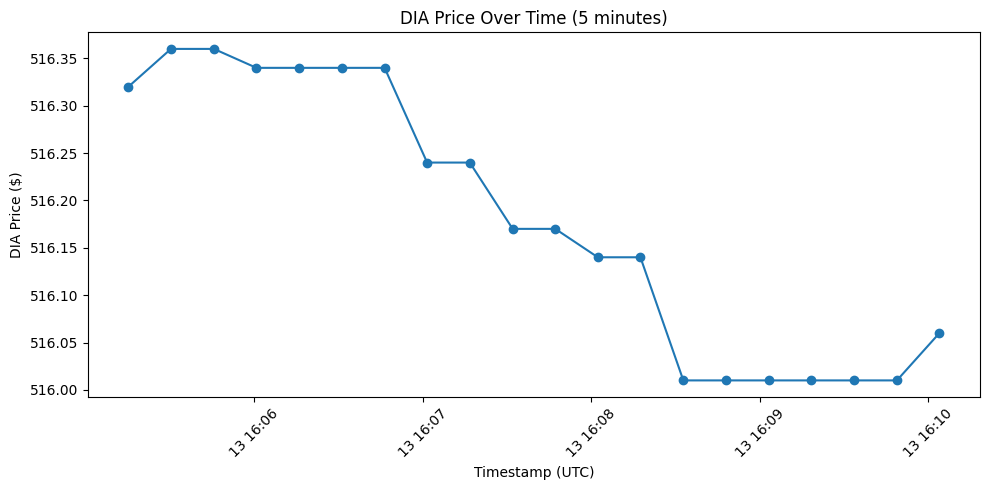

In [ ]:
import re
import pandas as pd
import matplotlib.pyplot as plt

# Paste your Java output between the triple quotes below
java_output = """
  Added data point: price=516.32, timestamp=2026-10-13T16:05:15.209056787Z
  Added data point: price=516.36, timestamp=2026-10-13T16:05:30.380970332Z
  Added data point: price=516.36, timestamp=2026-10-13T16:05:45.674130256Z
  Added data point: price=516.34, timestamp=2026-10-13T16:06:00.818594359Z
  Added data point: price=516.34, timestamp=2026-10-13T16:06:15.997561532Z
  Added data point: price=516.34, timestamp=2026-10-13T16:06:31.145325732Z
  Added data point: price=516.34, timestamp=2026-10-13T16:06:46.442470007Z
  Added data point: price=516.24, timestamp=2026-10-13T16:07:01.578692841Z
  Added data point: price=516.24, timestamp=2026-10-13T16:07:16.757549887Z
  Added data point: price=516.17, timestamp=2026-10-13T16:07:32.031897885Z
  Added data point: price=516.17, timestamp=2026-10-13T16:07:47.205529167Z
  Added data point: price=516.14, timestamp=2026-10-13T16:08:02.348360088Z
  Added data point: price=516.14, timestamp=2026-10-13T16:08:17.509407271Z
  Added data point: price=516.01, timestamp=2026-10-13T16:08:32.778204954Z
  Added data point: price=516.01, timestamp=2026-10-13T16:08:48.070896795Z
  Added data point: price=516.01, timestamp=2026-10-13T16:09:03.227358177Z
  Added data point: price=516.01, timestamp=2026-10-13T16:09:18.384454971Z
  Added data point: price=516.01, timestamp=2026-10-13T16:09:33.520697025Z
  Added data point: price=516.01, timestamp=2026-10-13T16:09:48.813382709Z
  Added data point: price=516.06, timestamp=2026-10-13T16:10:03.954503598Z
"""

# Extract price and timestamp
matches = re.findall(
    r"price=([0-9.]+), timestamp=([^\n]+)",
    java_output
)

# Convert to DataFrame
df = pd.DataFrame(matches, columns=["price", "timestamp"])

# Convert data types
df["price"] = df["price"].astype(float)
df["timestamp"] = pd.to_datetime(df["timestamp"])

print(df)

# Plot the data
plt.figure(figsize=(10, 5))
plt.plot(df["timestamp"], df["price"], marker="o")
plt.title("DIA Price Over Time (5 minutes)")
plt.xlabel("Timestamp (UTC)")
plt.ylabel("DIA Price ($)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Example Answer

        price                           timestamp
0  506.049988 2026-05-26 10:28:36.547871559+00:00
1  506.049988 2026-05-26 10:28:51.904412055+00:00


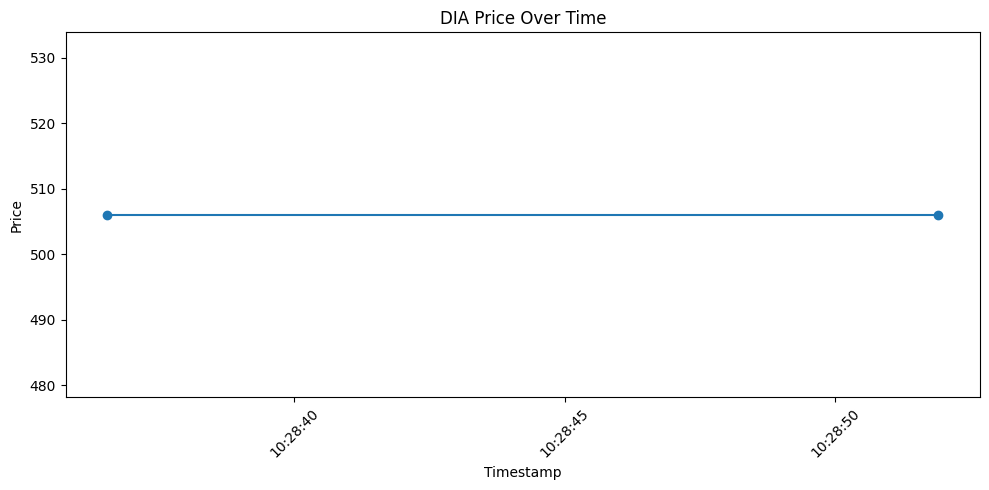

In [ ]:
import re
import pandas as pd
import matplotlib.pyplot as plt

# Paste your Java output between the triple quotes below
java_output = """
Request 1 of 2
HTTP status: 200
Raw response: {"price":"506.049988"}
Added data point: price=506.049988, timestamp=2026-05-26T10:28:36.547871559Z
Current queue size: 1
Waiting 15 seconds before the next request...

Request 2 of 2
HTTP status: 200
Raw response: {"price":"506.049988"}
Added data point: price=506.049988, timestamp=2026-05-26T10:28:51.904412055Z
Current queue size: 2
"""

# Extract price and timestamp values
matches = re.findall(
    r"Added data point: price=([0-9.]+), timestamp=([^\n]+)",
    java_output
)

# Convert to DataFrame
df = pd.DataFrame(matches, columns=["price", "timestamp"])

# Convert data types
df["price"] = df["price"].astype(float)
df["timestamp"] = pd.to_datetime(df["timestamp"])

# Display the data
print(df)

# Plot the data
plt.figure(figsize=(10, 5))
plt.plot(df["timestamp"], df["price"], marker="o")

plt.title("DIA Price Over Time")
plt.xlabel("Timestamp")
plt.ylabel("Price")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()